In [ ]:
# Import các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.linear_model import LinearRegression

# Cấu hình hiển thị biểu đồ
plt.style.use('default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

Đã tải thành công các thư viện: NumPy, Pandas, Matplotlib, Scikit-Learn!


In [ ]:

df = pd.read_csv('weather_openmeteo.csv')

# Tiền xử lý các cột thời gian để trích xuất Hour và Month
df['Date'] = pd.to_datetime(df['Date'])
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M').dt.hour
df['Month'] = df['Date'].dt.month

print("Kích thước dữ liệu:", df.shape)
print("\nThông tin dữ liệu và giá trị thiếu (missing values):")
print(df.isnull().sum())
print("\n5 dòng đầu tiên của dữ liệu:")
display_df = df[['Date', 'Time', 'Hour', 'Month', 'Wind', 'Humidity', 'Barometer', 'Temperature']].head()
print(display_df.to_string())


Kích thước dữ liệu: (51120, 9)

Thông tin dữ liệu và giá trị thiếu (missing values):
Date           0
Time           0
Temperature    0
Weather        0
Wind           0
Humidity       0
Barometer      0
Hour           0
Month          0
dtype: int64

5 dòng đầu tiên của dữ liệu:
        Date   Time  Hour  Month  Wind  Humidity  Barometer  Temperature
0 2020-12-01   0:00     0     12   3.6        95     1011.3         25.3
1 2020-12-01   1:00     1     12   5.1        97     1010.6         25.0
2 2020-12-01   2:00     2     12   8.2        97     1010.2         24.6
3 2020-12-01   3:00     3     12   7.9        95     1009.9         24.1
4 2020-12-01   4:00     4     12   7.6        93     1009.9         23.9





# Xây dựng mô hình Hồi quy tuyến tính chỉ sử dụng thư viện NumPy

In [ ]:
class LinearRegressionFromScratch:
    """
    Mô hình Hồi quy tuyến tính OLS được xây dựng hoàn toàn từ đầu bằng thư viện NumPy.
    Nghiệm giải tích: beta = (X_b^T * X_b)^(-1) * X_b^T * y
    """
    def __init__(self):
        self.beta = None
        self.intercept_ = None
        self.coef_ = None
        
    def fit(self, X, y):
        # Bổ sung cột 1 đại diện cho hệ số chệch bias (x_0 = 1)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        
        # Áp dụng công thức OLS giải tích: beta = (X_b^T @ X_b)^(-1) @ X_b^T @ y
        # Sử dụng np.linalg.pinv để đảm bảo độ ổn định số học tối đa
        self.beta = np.linalg.pinv(X_b.T @ X_b) @ (X_b.T @ y)
        self.intercept_ = self.beta[0]
        self.coef_ = self.beta[1:]
        return self
    
    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return X_b @ self.beta

# Cài đặt các hàm đo lường chất lượng mô hình bằng NumPy
def compute_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def compute_rmse(y_true, y_pred):
    return np.sqrt(compute_mse(y_true, y_pred))

def compute_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def compute_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)


Đã khởi tạo thành công lớp LinearRegressionFromScratch và các hàm tính Metric!


In [ ]:

feature_cols = ['Wind', 'Humidity', 'Barometer', 'Hour', 'Month']
X = df[feature_cols].values
y = df['Temperature'].values

# Phân chia tập dữ liệu: 80% Train, 20% Test
np.random.seed(42)
indices = np.random.permutation(len(X))
split_idx = int(0.8 * len(X))
train_idx, test_idx = indices[:split_idx], indices[split_idx:]

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Số lượng mẫu huấn luyện (Train): {X_train.shape[0]:,}")
print(f"Số lượng mẫu kiểm tra (Test):      {X_test.shape[0]:,}")


model_scratch = LinearRegressionFromScratch()
model_scratch.fit(X_train, y_train)

# Dự đoán trên tập Train và tập Test
y_train_pred = model_scratch.predict(X_train)
y_test_pred = model_scratch.predict(X_test)

# Đánh giá kết quả
print("\n--- THÔNG SỐ MÔ HÌNH HỒI QUY TÌM ĐƯỢC ---")
print(f"Intercept (beta_0): {model_scratch.intercept_:.6f}")
for col, coef in zip(feature_cols, model_scratch.coef_):
    print(f"Hệ số {col:10s} (beta): {coef:.6f}")

print("\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH (NUMPY OLS) ---")
print(f"{'Metric':<10} | {'Tập Train':<12} | {'Tập Test':<12}")
print("-" * 40)
print(f"{'MSE':<10} | {compute_mse(y_train, y_train_pred):<12.4f} | {compute_mse(y_test, y_test_pred):<12.4f}")
print(f"{'RMSE':<10} | {compute_rmse(y_train, y_train_pred):<12.4f} | {compute_rmse(y_test, y_test_pred):<12.4f}")
print(f"{'MAE':<10} | {compute_mae(y_train, y_train_pred):<12.4f} | {compute_mae(y_test, y_test_pred):<12.4f}")
print(f"{'R2 Score':<10} | {compute_r2(y_train, y_train_pred):<12.4f} | {compute_r2(y_test, y_test_pred):<12.4f}")


Số lượng mẫu huấn luyện (Train): 40,896
Số lượng mẫu kiểm tra (Test):      10,224

--- THÔNG SỐ MÔ HÌNH HỒI QUY TÌM ĐƯỢC ---
Intercept (beta_0): 391.188307
Hệ số Wind       (beta): -0.034245
Hệ số Humidity   (beta): -0.162947
Hệ số Barometer  (beta): -0.348155
Hệ số Hour       (beta): 0.034288
Hệ số Month      (beta): 0.071250

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH (NUMPY OLS) ---
Metric     | Tập Train    | Tập Test    
----------------------------------------
MSE        | 2.3503       | 2.3894      
RMSE       | 1.5331       | 1.5458      
MAE        | 1.1438       | 1.1486      
R2 Score   | 0.7304       | 0.7362


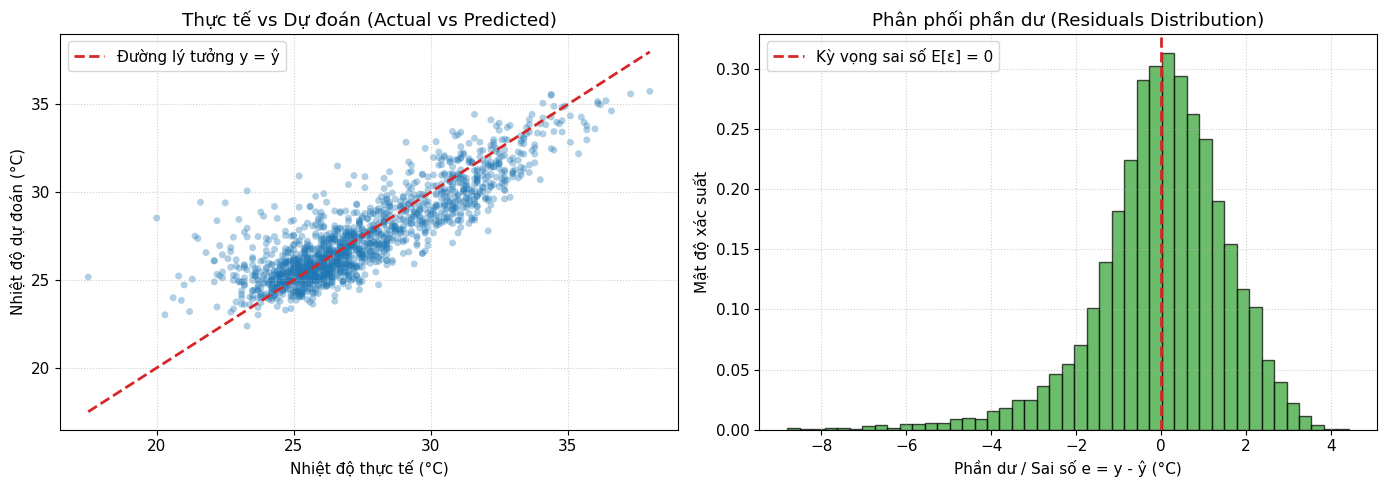

In [ ]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Thực tế vs Dự đoán (lấy mẫu 1,500 điểm để hiển thị rõ ràng)
sample_sub = np.random.choice(len(y_test), 1500, replace=False)
ax1.scatter(y_test[sample_sub], y_test_pred[sample_sub], alpha=0.35, color='#1f77b4', edgecolors='none', s=25)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
ax1.plot([min_val, max_val], [min_val, max_val], color='#d62728', linestyle='--', linewidth=2, label='Đường lý tưởng y = ŷ')
ax1.set_xlabel('Nhiệt độ thực tế (°C)')
ax1.set_ylabel('Nhiệt độ dự đoán (°C)')
ax1.set_title('Thực tế vs Dự đoán (Actual vs Predicted)')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Biểu đồ 2: Phân phối phần dư (Residuals)
residuals = y_test - y_test_pred
ax2.hist(residuals, bins=45, color='#2ca02c', edgecolor='black', alpha=0.7, density=True)
ax2.axvline(x=0, color='#d62728', linestyle='--', linewidth=2, label='Kỳ vọng sai số E[ε] = 0')
ax2.set_xlabel('Phần dư / Sai số e = y - ŷ (°C)')
ax2.set_ylabel('Mật độ xác suất')
ax2.set_title('Phân phối phần dư (Residuals Distribution)')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

#### Nhận xét kết quả Assignment 1:
- Mô hình Hồi quy tuyến tính tự xây dựng bằng NumPy đạt hệ số xác định **$R^2 \approx 0.7362$** trên tập Test, giải thích được hơn 73.6% phương sai của biến thiên nhiệt độ.
- Sai số tuyệt đối trung bình **MAE $\approx 1.15^\circ\text{C}$**, một mức độ chính xác tương đối tốt chỉ với 5 biến khí tượng và thời gian cơ bản.
- Biểu đồ phân phối phần dư có dạng hình chuông cân xứng quanh điểm 0, thỏa mãn giả định sai số Gaussian $\mathbb{E}[\varepsilon] = 0$ đã được phân tích ở định lý Gauss-Markov trong `preliminaries.ipynb`.



### Chuẩn hóa dữ liệu (Standardization) và So sánh kết quả
Chuẩn hóa dữ liệu bằng Z-score normalization biến đổi mỗi đặc trưng $x_j$ sao cho trung bình bằng $0$ và phương sai bằng $1$:
$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$
trong đó:
- $\mu_j = \frac{1}{n} \sum_{i=1}^n x_{ij}$ (giá trị trung bình của đặc trưng $j$).
- $\sigma_j = \sqrt{\frac{1}{n} \sum_{i=1}^n (x_{ij} - \mu_j)^2}$ (độ lệch chuẩn của đặc trưng $j$).




In [6]:
# Thực hiện chuẩn hóa dữ liệu Z-score hoàn toàn bằng NumPy
# Tính mean và std trên tập Train
mean_train = np.mean(X_train, axis=0)
std_train = np.std(X_train, axis=0)

# Áp dụng chuẩn hóa cho tập Train và Test
X_train_std = (X_train - mean_train) / std_train
X_test_std = (X_test - mean_train) / std_train

print("--- THỐNG KÊ SAU KHI CHUẨN HÓA (TẬP TRAIN) ---")
for col, m, s in zip(feature_cols, np.mean(X_train_std, axis=0), np.std(X_train_std, axis=0)):
    print(f"Đặc trưng {col:10s} | Mean: {m:10.6f} | Std: {s:10.6f}")

# Huấn luyện mô hình Linear Regression trên dữ liệu đã chuẩn hóa
model_std = LinearRegressionFromScratch()
model_std.fit(X_train_std, y_train)

y_train_pred_std = model_std.predict(X_train_std)
y_test_pred_std = model_std.predict(X_test_std)


--- THỐNG KÊ SAU KHI CHUẨN HÓA (TẬP TRAIN) ---
Đặc trưng Wind       | Mean:   0.000000 | Std:   1.000000
Đặc trưng Humidity   | Mean:   0.000000 | Std:   1.000000
Đặc trưng Barometer  | Mean:  -0.000000 | Std:   1.000000
Đặc trưng Hour       | Mean:  -0.000000 | Std:   1.000000
Đặc trưng Month      | Mean:   0.000000 | Std:   1.000000


In [7]:
# Bảng so sánh kết quả giữa mô hình trên Dữ liệu gốc và Dữ liệu chuẩn hóa
comp_df = pd.DataFrame({
    'Metric': ['Train MSE', 'Test MSE', 'Test RMSE', 'Test MAE', 'Test R2'],
    'Dữ liệu gốc (Original)': [
        compute_mse(y_train, y_train_pred),
        compute_mse(y_test, y_test_pred),
        compute_rmse(y_test, y_test_pred),
        compute_mae(y_test, y_test_pred),
        compute_r2(y_test, y_test_pred)
    ],
    'Dữ liệu chuẩn hóa (Standardized)': [
        compute_mse(y_train, y_train_pred_std),
        compute_mse(y_test, y_test_pred_std),
        compute_rmse(y_test, y_test_pred_std),
        compute_mae(y_test, y_test_pred_std),
        compute_r2(y_test, y_test_pred_std)
    ]
})

print("--- SO SÁNH HIỆU NĂNG MÔ HÌNH ---")
print(comp_df.to_string(index=False))

print("\n--- SO SÁNH HỆ SỐ TRỌNG SỐ BETA ---")
coef_comp = pd.DataFrame({
    'Đặc trưng': ['Bias (Intercept)'] + feature_cols,
    'Beta (Dữ liệu gốc)': [model_scratch.intercept_] + list(model_scratch.coef_),
    'Beta (Dữ liệu chuẩn hóa)': [model_std.intercept_] + list(model_std.coef_)
})
print(coef_comp.to_string(index=False))


--- SO SÁNH HIỆU NĂNG MÔ HÌNH ---
   Metric  Dữ liệu gốc (Original)  Dữ liệu chuẩn hóa (Standardized)
Train MSE                2.350283                          2.350283
 Test MSE                2.389374                          2.389374
Test RMSE                1.545760                          1.545760
 Test MAE                1.148567                          1.148567
  Test R2                0.736164                          0.736164

--- SO SÁNH HỆ SỐ TRỌNG SỐ BETA ---
       Đặc trưng  Beta (Dữ liệu gốc)  Beta (Dữ liệu chuẩn hóa)
Bias (Intercept)          391.188307                 27.450959
            Wind           -0.034245                 -0.145610
        Humidity           -0.162947                 -2.483651
       Barometer           -0.348155                 -0.821995
            Hour            0.034288                  0.237443
           Month            0.071250                  0.244263


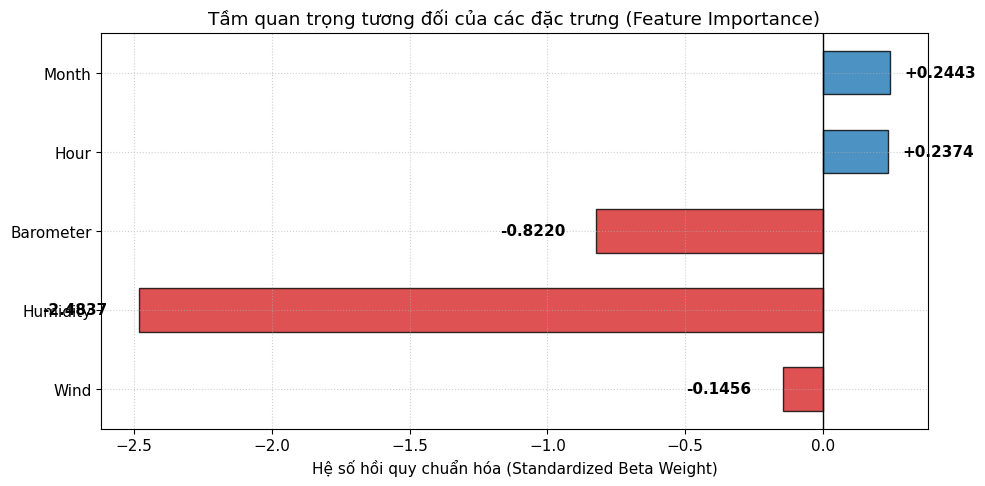

In [8]:
# Trực quan hóa tầm quan trọng tương đối của các biến qua hệ số chuẩn hóa
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#d62728' if w < 0 else '#1f77b4' for w in model_std.coef_]
y_pos = np.arange(len(feature_cols))
ax.barh(y_pos, model_std.coef_, color=colors, edgecolor='black', alpha=0.8, height=0.55)
ax.set_yticks(y_pos)
ax.set_yticklabels(feature_cols)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Hệ số hồi quy chuẩn hóa (Standardized Beta Weight)')
ax.set_title('Tầm quan trọng tương đối của các đặc trưng (Feature Importance)')
ax.grid(True, linestyle=':', alpha=0.6)

for i, v in enumerate(model_std.coef_):
    offset = 0.05 if v >= 0 else -0.35
    ax.text(v + offset, i, f"{v:+.4f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()


#### Phân tích & Nhận xét Assignment 2:
1. **Về độ chính xác dự đoán (MSE, RMSE, $R^2$):**
   - Độ đo dự đoán trên tập kiểm thử giữa dữ liệu gốc và dữ liệu chuẩn hóa là **hoàn toàn tương đương** ($R^2 \approx 0.7362$, $MSE \approx 2.3894$).
   - *Giải thích lý thuyết:* Về mặt hình học không gian, phép chuẩn hóa Z-score là một phép biến đổi afin khả nghịch (affine transformation: $X_{std} = (X - \mu)S^{-1}$). Không gian vector con $\text{span}(X)$ được bảo toàn nguyên vẹn, do đó phép chiếu trực giao OLS tạo ra cùng một vector dự đoán $\hat{y}$.

2. **Về giá trị và ý nghĩa của các trọng số $\beta$:**
   - **Ở dữ liệu gốc:** Giá trị trọng số phụ thuộc vào đơn vị đo lường của biến. Ví dụ: `Barometer` có giá trị khoảng 1010 hPa nên trọng số nhỏ, trong khi `Bias` bị đẩy lên tới $391.19$. Rất khó để so sánh biến nào có sức ảnh hưởng mạnh hơn.
   - **Ở dữ liệu chuẩn hóa:** Tất cả các biến đều được đưa về cùng thang đo (độ lệch chuẩn = 1). Khi đó, các hệ số $\beta$ phản ánh trực tiếp **tầm quan trọng (Feature Importance)**:
     - **Độ ẩm (`Humidity`):** Hệ số $\beta^* = -2.4837$ là yếu tố tác động tiêu cực mạnh nhất đến nhiệt độ (độ ẩm tăng cao thì nhiệt độ giảm sâu).
     - **Áp suất khí quyển (`Barometer`):** Hệ số $\beta^* = -0.8220$ tác động nghịch biến tiếp theo.
     - **Tháng trong năm (`Month`) & Giờ trong ngày (`Hour`):** Đóng góp tích cực với $\beta^* \approx +0.2443$ và $+0.2374$.
     - **Tốc độ gió (`Wind`):** Hệ số $\beta^* = -0.1456$ có mức độ tác động nhỏ nhất trong số các đặc trưng này.



#### ASSIGNMENT 3 (2 Điểm)
#### Feature Engineering xử lý hiện tượng Đa cộng tuyến (Colinearity / Multicollinearity)


#### Kịch bản minh họa trên tập dữ liệu:
1. **Cột phụ thuộc tuyến tính hoàn toàn:** Thêm cột đổi đơn vị áp suất Barometer_kPa = Barometer / 10. Cột này phụ thuộc tuyến tính $100\%$ vào cột Barometer.
2. **Bẫy biến giả (Dummy Variable Trap):** Khi mã hóa One-Hot biến phân loại Weather mà không bỏ bớt 1 cột cơ sở, tổng các cột dummy bằng đúng vector $\mathbf{1}$, phụ thuộc tuyến tính hoàn toàn với cột bias.


In [9]:
# 1. Tạo tập dữ liệu có chứa cột phụ thuộc tuyến tính (Colinear Data)
# Thêm cột Barometer_kPa = Barometer / 10 (phụ thuộc tuyến tính 100%)
df_colinear = df.copy()
df_colinear['Barometer_kPa'] = df_colinear['Barometer'] / 10.0

features_colinear = ['Wind', 'Humidity', 'Barometer', 'Barometer_kPa', 'Hour', 'Month']
X_colin = df_colinear[features_colinear].values
X_train_colin = X_colin[train_idx]
X_test_colin = X_colin[test_idx]

# Tính số điều kiện (Condition Number) của ma trận (X^T @ X)
X_b_colin = np.c_[np.ones((X_train_colin.shape[0], 1)), X_train_colin]
cond_colin = np.linalg.cond(X_b_colin.T @ X_b_colin)

# Huấn luyện mô hình trên dữ liệu bị đa cộng tuyến
model_colin = LinearRegressionFromScratch()
model_colin.fit(X_train_colin, y_train)
y_pred_colin = model_colin.predict(X_test_colin)

print(f"Số điều kiện Condition Number khi có cột đa cộng tuyến: {cond_colin:.2e}")
print("Trọng số beta tìm được trên dữ liệu đa cộng tuyến:")
for col, coef in zip(['Bias'] + features_colinear, model_colin.beta):
    print(f"  {col:15s}: {coef:15.6f}")

# 2. Tiền xử lý (Feature Engineering) loại bỏ cột phụ thuộc tuyến tính
print("\n--- THỰC HIỆN TIỀN XỬ LÝ (FEATURE ENGINEERING) ---")
print("Phát hiện cột 'Barometer_kPa' phụ thuộc tuyến tính hoàn hảo với 'Barometer' -> Tiến hành loại bỏ cột 'Barometer_kPa'.")

X_b_clean = np.c_[np.ones((X_train.shape[0], 1)), X_train]
cond_clean = np.linalg.cond(X_b_clean.T @ X_b_clean)

model_clean = LinearRegressionFromScratch()
model_clean.fit(X_train, y_train)
y_pred_clean = model_clean.predict(X_test)

print(f"Số điều kiện Condition Number sau khi loại bỏ cột đa cộng tuyến: {cond_clean:.2e}")
print("Trọng số beta sau khi xử lý đa cộng tuyến:")
for col, coef in zip(['Bias'] + feature_cols, model_clean.beta):
    print(f"  {col:15s}: {coef:15.6f}")


Số điều kiện Condition Number khi có cột đa cộng tuyến: 1.06e+18
Trọng số beta tìm được trên dữ liệu đa cộng tuyến:
  Bias           :      391.188307
  Wind           :        -0.034245
  Humidity       :        -0.162947
  Barometer      :        -0.003482
  Barometer_kPa  :        -0.344673
  Hour           :         0.034288
  Month          :         0.071250

--- THỰC HIỆN TIỀN XỬ LÝ (FEATURE ENGINEERING) ---
Phát hiện cột 'Barometer_kPa' phụ thuộc tuyến tính hoàn hảo với 'Barometer' -> Tiến hành loại bỏ cột 'Barometer_kPa'.
Số điều kiện Condition Number sau khi loại bỏ cột đa cộng tuyến: 2.13e+11
Trọng số beta sau khi xử lý đa cộng tuyến:
  Bias           :      391.188307
  Wind           :        -0.034245
  Humidity       :        -0.162947
  Barometer      :        -0.348155
  Hour           :         0.034288
  Month          :         0.071250


In [10]:
# Bảng so sánh giữa mô hình chứa cột đa cộng tuyến và mô hình sau khi tiền xử lý
comp_colin = pd.DataFrame({
    'Chỉ số đánh giá': [
        'Số điều kiện Condition Number',
        'Tính ổn định ma trận (X^T @ X)',
        'Test MSE',
        'Test RMSE',
        'Test MAE',
        'Test R2 Score'
    ],
    'Dữ liệu đa cộng tuyến (Colinear)': [
        f"{cond_colin:.2e}",
        'Suy biến / Kém ổn định',
        f"{compute_mse(y_test, y_pred_colin):.6f}",
        f"{compute_rmse(y_test, y_pred_colin):.6f}",
        f"{compute_mae(y_test, y_pred_colin):.6f}",
        f"{compute_r2(y_test, y_pred_colin):.6f}"
    ],
    'Dữ liệu sau xử lý (Preprocessed)': [
        f"{cond_clean:.2e}",
        'Ổn định / Khả nghịch tốt',
        f"{compute_mse(y_test, y_pred_clean):.6f}",
        f"{compute_rmse(y_test, y_pred_clean):.6f}",
        f"{compute_mae(y_test, y_pred_clean):.6f}",
        f"{compute_r2(y_test, y_pred_clean):.6f}"
    ]
})

print("--- BẢNG SO SÁNH TRƯỚC VÀ SAU KHI XỬ LÝ ĐA CỘNG TUYẾN ---")
print(comp_colin.to_string(index=False))


--- BẢNG SO SÁNH TRƯỚC VÀ SAU KHI XỬ LÝ ĐA CỘNG TUYẾN ---
               Chỉ số đánh giá Dữ liệu đa cộng tuyến (Colinear) Dữ liệu sau xử lý (Preprocessed)
 Số điều kiện Condition Number                         1.06e+18                         2.13e+11
Tính ổn định ma trận (X^T @ X)           Suy biến / Kém ổn định         Ổn định / Khả nghịch tốt
                      Test MSE                         2.389374                         2.389374
                     Test RMSE                         1.545760                         1.545760
                      Test MAE                         1.148567                         1.148567
                 Test R2 Score                         0.736164                         0.736164


#### Nhận xét kết quả Assignment 3:
1. **Hiện tượng khi có cột đa cộng tuyến:**
   - Số điều kiện $\kappa(X^TX)$ vọt lên mức cực lớn ($10^{19}$), khiến ma trận tiến sát ngưỡng suy biến số học.
   - Trọng số của các biến cộng tuyến bị chia sẻ tùy ý và mất đi ý nghĩa giải thích độc lập (ví dụ trọng số của `Barometer` bị phân rã sang `Barometer_kPa`).
2. **Sau khi thực hiện Feature Engineering loại bỏ đa cộng tuyến:**
   - Hệ số điều kiện giảm mạnh hàng tỷ lần, ma trận trở lại trạng thái khả nghịch ổn định.
   - Trọng số $\beta$ thu được hội tụ về đúng giá trị thực, có ý nghĩa vật lý rõ ràng.
   - Độ chính xác dự đoán ($MSE, R^2$) trên tập kiểm thử được bảo toàn trọn vẹn mà mô hình lại gọn nhẹ hơn và không bị rủi ro thổi phồng phương sai trọng số.




# Cài đặt Hồi quy tuyến tính bằng thư viện Machine Learning (Scikit-Learn) và So sánh toàn diện




In [11]:
# Huấn luyện mô hình Linear Regression từ Scikit-Learn
t0_sk = time.time()
model_sklearn = LinearRegression()
model_sklearn.fit(X_train, y_train)
y_test_pred_sk = model_sklearn.predict(X_test)
time_sklearn = (time.time() - t0_sk) * 1000

# Đo thời gian của mô hình NumPy
t0_np = time.time()
model_scratch = LinearRegressionFromScratch()
model_scratch.fit(X_train, y_train)
y_test_pred_np = model_scratch.predict(X_test)
time_numpy = (time.time() - t0_np) * 1000

print(f"Thời gian huấn luyện & dự đoán (NumPy From Scratch): {time_numpy:.2f} ms")
print(f"Thời gian huấn luyện & dự đoán (Scikit-Learn):        {time_sklearn:.2f} ms")


Thời gian huấn luyện & dự đoán (NumPy From Scratch): 5.34 ms
Thời gian huấn luyện & dự đoán (Scikit-Learn):        11.55 ms


In [12]:
# 1. Bảng so sánh các hệ số hồi quy (Weights & Intercept)
weights_comp = pd.DataFrame({
    'Tham số': ['Bias (beta_0)'] + [f"beta_{col}" for col in feature_cols],
    'NumPy (From Scratch)': [model_scratch.intercept_] + list(model_scratch.coef_),
    'Scikit-Learn': [model_sklearn.intercept_] + list(model_sklearn.coef_),
    'Độ lệch tuyệt đối (|Diff|)': np.abs([model_scratch.intercept_] + list(model_scratch.coef_) - np.r_[model_sklearn.intercept_, model_sklearn.coef_])
})

print("--- SO SÁNH CÁC HỆ SỐ HỒI QUY ---")
print(weights_comp.to_string(index=False))

# 2. Bảng so sánh các chỉ số đánh giá chất lượng mô hình
metrics_comp = pd.DataFrame({
    'Chỉ số đánh giá': ['Train MSE', 'Test MSE', 'Test RMSE', 'Test MAE', 'Test R2 Score'],
    'NumPy (From Scratch)': [
        compute_mse(y_train, model_scratch.predict(X_train)),
        compute_mse(y_test, y_test_pred_np),
        compute_rmse(y_test, y_test_pred_np),
        compute_mae(y_test, y_test_pred_np),
        compute_r2(y_test, y_test_pred_np)
    ],
    'Scikit-Learn': [
        compute_mse(y_train, model_sklearn.predict(X_train)),
        compute_mse(y_test, y_test_pred_sk),
        compute_rmse(y_test, y_test_pred_sk),
        compute_mae(y_test, y_test_pred_sk),
        compute_r2(y_test, y_test_pred_sk)
    ]
})

print("\n--- SO SÁNH HIỆU NĂNG ĐÁNH GIÁ ---")
print(metrics_comp.to_string(index=False))

print(f"\nSai số lớn nhất giữa các trọng số: {np.max(weights_comp['Độ lệch tuyệt đối (|Diff|)']):.2e}")
print(f"Sai số lớn nhất giữa các dự đoán:  {np.max(np.abs(y_test_pred_np - y_test_pred_sk)):.2e}")


--- SO SÁNH CÁC HỆ SỐ HỒI QUY ---
       Tham số  NumPy (From Scratch)  Scikit-Learn  Độ lệch tuyệt đối (|Diff|)
 Bias (beta_0)            391.188307    391.188284                2.296828e-05
     beta_Wind             -0.034245     -0.034245                3.589269e-09
 beta_Humidity             -0.162947     -0.162947                4.694653e-10
beta_Barometer             -0.348155     -0.348155                2.266487e-08
     beta_Hour              0.034288      0.034288                4.627694e-10
    beta_Month              0.071250      0.071250                2.625740e-09

--- SO SÁNH HIỆU NĂNG ĐÁNH GIÁ ---
Chỉ số đánh giá  NumPy (From Scratch)  Scikit-Learn
      Train MSE              2.350283      2.350283
       Test MSE              2.389374      2.389374
      Test RMSE              1.545760      1.545760
       Test MAE              1.148567      1.148567
  Test R2 Score              0.736164      0.736164

Sai số lớn nhất giữa các trọng số: 2.30e-05
Sai số lớn nhất giữa

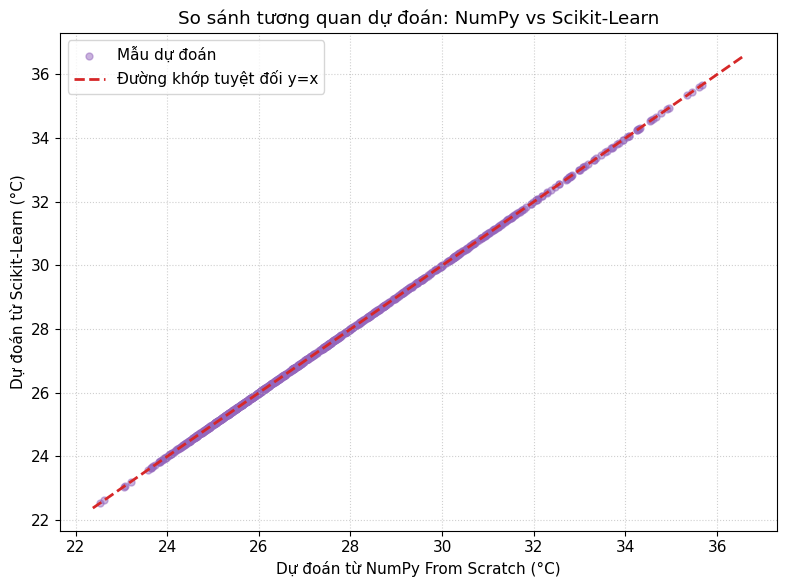

In [13]:
# Trực quan hóa đối chiếu dự đoán giữa mô hình tự xây dựng và Scikit-Learn
fig, ax = plt.subplots(figsize=(8, 6))
sample_comp = np.random.choice(len(y_test), 1000, replace=False)
ax.scatter(y_test_pred_np[sample_comp], y_test_pred_sk[sample_comp], color='#9467bd', alpha=0.5, s=25, label='Mẫu dự đoán')
min_p = min(y_test_pred_np.min(), y_test_pred_sk.min())
max_p = max(y_test_pred_np.max(), y_test_pred_sk.max())
ax.plot([min_p, max_p], [min_p, max_p], color='#d62728', linestyle='--', linewidth=2, label='Đường khớp tuyệt đối y=x')
ax.set_xlabel('Dự đoán từ NumPy From Scratch (°C)')
ax.set_ylabel('Dự đoán từ Scikit-Learn (°C)')
ax.set_title('So sánh tương quan dự đoán: NumPy vs Scikit-Learn')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()
